# End-to-End Medical Machine Learning Capstone

## Diabetes Prediction Using Machine Learning

### Project Overview

Diabetes is a common chronic disease that requires early detection and appropriate medical management. Machine learning can be used to analyze patient-related clinical measurements and predict whether a patient is likely to have diabetes.

In this project, a supervised machine learning classification pipeline will be developed using a diabetes medical dataset. The workflow will include data exploration, preprocessing, feature scaling, model training, performance evaluation, and comparison of multiple machine learning algorithms.

The following classification algorithms will be compared:

* Logistic Regression
* Decision Tree
* Random Forest

The models will be evaluated using Accuracy, Precision, Recall, and F1-score. The final model will be selected based on its predictive performance and its suitability for a potential clinical decision-support workflow.


In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/alaanasr5575/pima-indians-diabetes-database/diabetes.csv


In [4]:
# Load the dataset

df = pd.read_csv(
    '/kaggle/input/datasets/alaanasr5575/pima-indians-diabetes-database/diabetes.csv'
)

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Dataset Inspection

Before building the machine learning models, the dataset is inspected to understand its structure, number of observations, and available features.

In [5]:
# Check the number of rows and columns

df.shape


(768, 9)

In [6]:
# Display column names

df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

### Dataset Structure

The dataset contains eight predictor variables and one target variable. The predictor variables represent demographic and clinical measurements, while `Outcome` is the target variable used for diabetes classification.

In [7]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
# Statistical summary of numerical features

df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
# Check for missing values

df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [11]:
df.shape

(768, 9)

In [12]:
df.columns


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [14]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [15]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of the target variable and identify potential data-quality issues before model training.

In [16]:
# Check the distribution of the target variable

df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

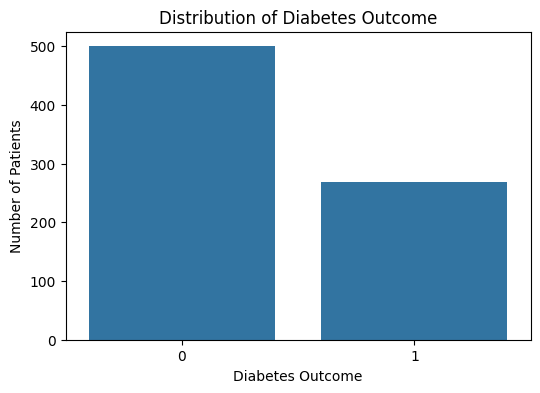

In [17]:
# Visualize the target distribution

plt.figure(figsize=(6, 4))

sns.countplot(x='Outcome', data=df)

plt.title('Distribution of Diabetes Outcome')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Number of Patients')

plt.show()

In [18]:
# Calculate the percentage of each outcome

df['Outcome'].value_counts(normalize=True) * 100

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

In [19]:
# Count zero values in each column

zero_counts = (df == 0).sum()

zero_counts

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

## Feature Correlation Analysis

A correlation analysis is used to examine the relationships between the numerical features and the diabetes outcome. This can help identify features that may contain useful predictive information.

In [22]:
# Calculate the correlation matrix

correlation_matrix = df.corr()

correlation_matrix


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


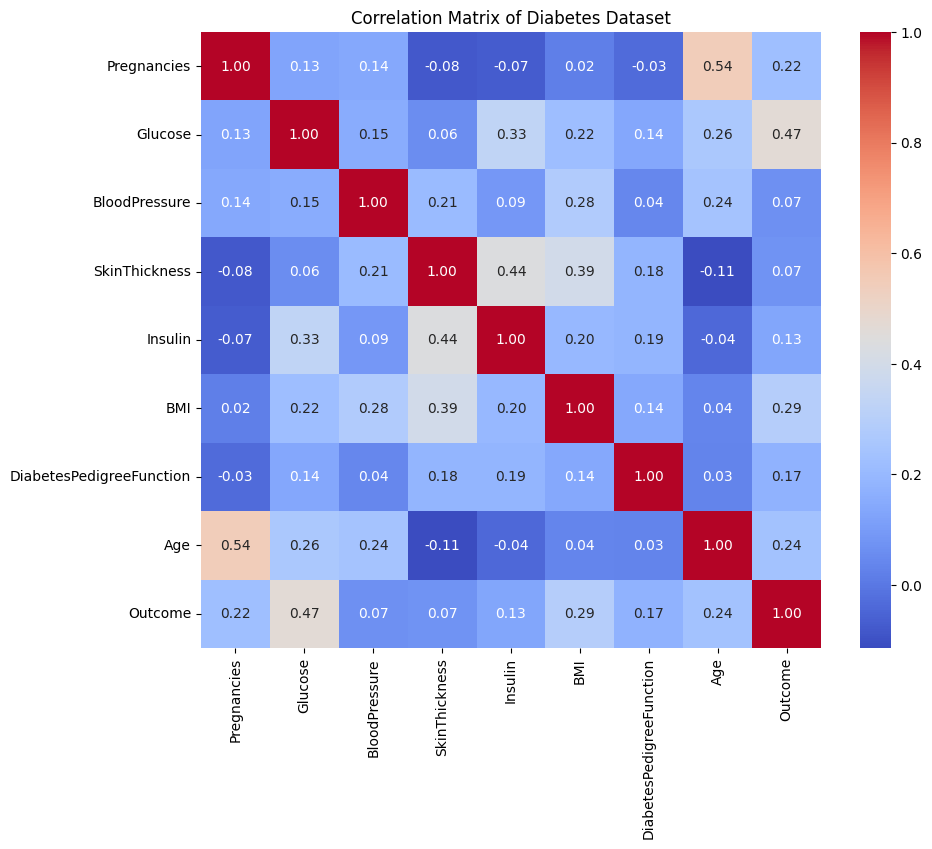

In [23]:
# Visualize the correlation matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Diabetes Dataset')

plt.show()

## Feature Distribution by Diabetes Outcome

The average values of the clinical features are compared between patients with and without diabetes. This provides an initial understanding of how the patient characteristics differ across the two outcome groups.

In [24]:
# Compare average feature values by diabetes outcome

df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


## EDA Findings

The exploratory analysis shows that the dataset contains 768 observations and 9 variables, including eight predictive features and one binary target variable.

The target variable is moderately imbalanced, with 65.10% of observations belonging to the non-diabetic class (Outcome = 0) and 34.90% belonging to the diabetic class (Outcome = 1).

The correlation analysis indicates that Glucose has the strongest positive correlation with the diabetes outcome (0.47), followed by BMI (0.29), Age (0.24), and Pregnancies (0.22).

Comparing the mean feature values between the two outcome groups also shows noticeable differences. Patients with Outcome = 1 have higher average Glucose, BMI, Age, and Pregnancies values than patients with Outcome = 0.

These findings suggest that the available clinical features contain useful information for predicting diabetes, while also highlighting the importance of appropriate preprocessing before model training.

## Data Preprocessing

Some clinical variables contain zero values that are not physiologically plausible and may represent missing measurements. These values will be treated as missing data for Glucose, BloodPressure, SkinThickness, Insulin, and BMI.

The Pregnancies and Outcome variables will not be modified because zero is a valid value for these variables.

In [29]:
# Create a copy of the original dataset

df_clean = df.copy()

In [30]:
# Replace physiologically invalid zero values with NaN

invalid_zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df_clean[invalid_zero_columns] = df_clean[invalid_zero_columns].replace(0, np.nan)

df_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

### Handling Missing Values

The invalid zero values identified in selected clinical features are treated as missing values. These missing values will be imputed using the median of each feature.

Median imputation is used because it is less sensitive to extreme values and is suitable for numerical medical measurements.

In [33]:
# Fill missing values using the median of each feature

for column in invalid_zero_columns:
    df_clean[column].fillna(df_clean[column].median(), inplace=True)

In [34]:
# Verify that missing values have been handled

df_clean.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [35]:
df_clean.shape

(768, 9)


## Feature and Target Selection

The `Outcome` column is the target variable that indicates whether a patient has diabetes. The remaining eight clinical and demographic variables are used as predictive features.

The dataset will be divided into training, validation, and testing sets before applying preprocessing transformations. The preprocessing steps will be fitted only on the training set and then applied to the validation and test sets to prevent data leakage.

In [64]:
# Define features and target

X_raw = df.copy()

invalid_zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

X_raw[invalid_zero_columns] = X_raw[invalid_zero_columns].replace(0, np.nan)

X = X_raw.drop('Outcome', axis=1)
y = X_raw['Outcome']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


## Train, Validation, and Test Split

The dataset is divided into training, validation, and testing subsets.

The training set is used to train the machine learning models. The validation set is used to compare model performance and support model selection, while the test set is kept completely unseen until the final evaluation.

Stratified splitting is used to preserve the distribution of diabetic and non-diabetic cases across the three subsets.

In [45]:
# First split: 70% training and 30% temporary data

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the temporary data equally
# into validation and test sets

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (537, 8)
Validation set: (115, 8)
Testing set: (116, 8)


In [46]:
from sklearn.impute import SimpleImputer

# Imputation
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (537, 8)
Validation: (115, 8)
Test: (116, 8)


## Model 1: Logistic Regression

Logistic Regression is used as the first classification model in this project.

It estimates the probability that a patient belongs to the diabetic class based on the available clinical features.

The model is trained using the training set and evaluated on the validation set for model comparison.

In [47]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(random_state=42)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [48]:
# Predict the validation set
y_pred_lr = logistic_model.predict(X_val_scaled)

print("Logistic Regression predictions:")
print(y_pred_lr[:10])

Logistic Regression predictions:
[0 1 0 0 0 0 0 0 1 0]


In [51]:
# Evaluate Logistic Regression on the Validation Set

lr_accuracy = accuracy_score(y_val, y_pred_lr)
lr_precision = precision_score(y_val, y_pred_lr)
lr_recall = recall_score(y_val, y_pred_lr)
lr_f1 = f1_score(y_val, y_pred_lr)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy:  0.7130
Precision: 0.5946
Recall:    0.5500
F1-score:  0.5714


## Model 2: Decision Tree

Decision Tree is used as the second classification model in this project.

The model makes predictions by splitting the data into branches based on the feature values. It is easy to interpret and can capture non-linear relationships between clinical features and diabetes outcomes.

The model is trained using the training set and evaluated on the validation set.

In [52]:
# Create the Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [53]:
# Predict and evaluate Decision Tree on the Validation Set

y_pred_dt = decision_tree_model.predict(X_val_scaled)

dt_accuracy = accuracy_score(y_val, y_pred_dt)
dt_precision = precision_score(y_val, y_pred_dt)
dt_recall = recall_score(y_val, y_pred_dt)
dt_f1 = f1_score(y_val, y_pred_dt)

print("Decision Tree Performance")
print("-------------------------")
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1-score:  {dt_f1:.4f}")

Decision Tree Performance
-------------------------
Accuracy:  0.7217
Precision: 0.5952
Recall:    0.6250
F1-score:  0.6098


## Model 3: Random Forest

Random Forest is used as the third classification model in this project.

It combines multiple decision trees and aggregates their predictions to improve generalization and reduce the risk of overfitting compared with a single decision tree.

The model is trained using the training set and evaluated on the validation set.

In [54]:
# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [55]:
# Predict and evaluate Random Forest on the Validation Set

y_pred_rf = random_forest_model.predict(X_val_scaled)

rf_accuracy = accuracy_score(y_val, y_pred_rf)
rf_precision = precision_score(y_val, y_pred_rf)
rf_recall = recall_score(y_val, y_pred_rf)
rf_f1 = f1_score(y_val, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")

Random Forest Performance
-------------------------
Accuracy:  0.7478
Precision: 0.6486
Recall:    0.6000
F1-score:  0.6234


## Model Performance Comparison

The three classification models are compared using the validation set based on Accuracy, Precision, Recall, and F1-score.

The validation results are used to identify the best-performing model before performing the final evaluation on the unseen test set.

In [57]:
# Create a comparison table

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    'Precision': [
        lr_precision,
        dt_precision,
        rf_precision
    ],
    'Recall': [
        lr_recall,
        dt_recall,
        rf_recall
    ],
    'F1-score': [
        lr_f1,
        dt_f1,
        rf_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.713043,0.594595,0.550,0.571429
1,Decision Tree,0.721739,0.595238,0.625,0.609756
2,Random Forest,0.747826,0.648649,0.600,0.623377


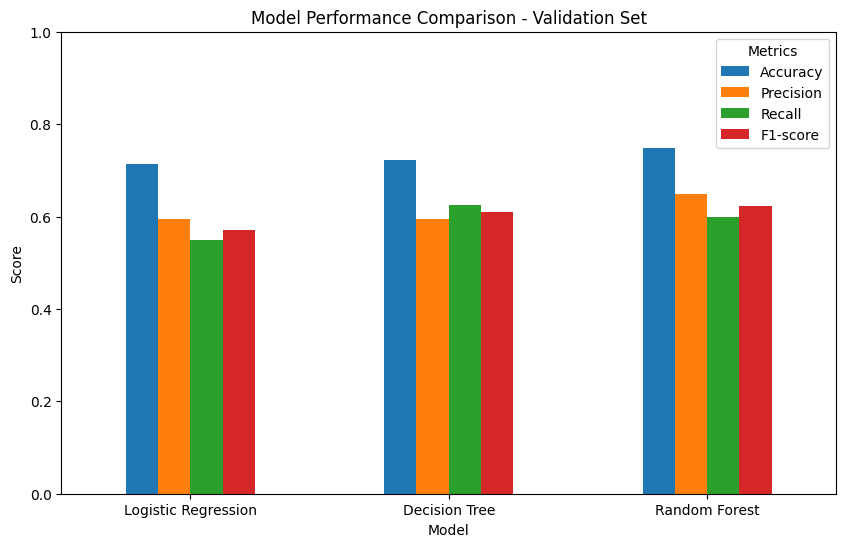

In [58]:
# Visualize model performance

results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison - Validation Set')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.show()

## Final Test Evaluation

After comparing the three models on the validation set, all models are evaluated on the previously unseen test set.

The test set is used only for the final performance assessment. Accuracy, Precision, Recall, and F1-score are reported for each model.

In [59]:
# Final Test Evaluation for All Models

# Logistic Regression
y_pred_lr_test = logistic_model.predict(X_test_scaled)

lr_test_accuracy = accuracy_score(y_test, y_pred_lr_test)
lr_test_precision = precision_score(y_test, y_pred_lr_test)
lr_test_recall = recall_score(y_test, y_pred_lr_test)
lr_test_f1 = f1_score(y_test, y_pred_lr_test)


# Decision Tree
y_pred_dt_test = decision_tree_model.predict(X_test_scaled)

dt_test_accuracy = accuracy_score(y_test, y_pred_dt_test)
dt_test_precision = precision_score(y_test, y_pred_dt_test)
dt_test_recall = recall_score(y_test, y_pred_dt_test)
dt_test_f1 = f1_score(y_test, y_pred_dt_test)


# Random Forest
y_pred_rf_test = random_forest_model.predict(X_test_scaled)

rf_test_accuracy = accuracy_score(y_test, y_pred_rf_test)
rf_test_precision = precision_score(y_test, y_pred_rf_test)
rf_test_recall = recall_score(y_test, y_pred_rf_test)
rf_test_f1 = f1_score(y_test, y_pred_rf_test)


# Display results
print("Final Test Performance")
print("======================")

print("\nLogistic Regression")
print("-------------------")
print(f"Accuracy:  {lr_test_accuracy:.4f}")
print(f"Precision: {lr_test_precision:.4f}")
print(f"Recall:    {lr_test_recall:.4f}")
print(f"F1-score:  {lr_test_f1:.4f}")

print("\nDecision Tree")
print("-------------")
print(f"Accuracy:  {dt_test_accuracy:.4f}")
print(f"Precision: {dt_test_precision:.4f}")
print(f"Recall:    {dt_test_recall:.4f}")
print(f"F1-score:  {dt_test_f1:.4f}")

print("\nRandom Forest")
print("-------------")
print(f"Accuracy:  {rf_test_accuracy:.4f}")
print(f"Precision: {rf_test_precision:.4f}")
print(f"Recall:    {rf_test_recall:.4f}")
print(f"F1-score:  {rf_test_f1:.4f}")

Final Test Performance

Logistic Regression
-------------------
Accuracy:  0.7759
Precision: 0.7778
Recall:    0.5122
F1-score:  0.6176

Decision Tree
-------------
Accuracy:  0.6724
Precision: 0.5455
Recall:    0.4390
F1-score:  0.4865

Random Forest
-------------
Accuracy:  0.7500
Precision: 0.7000
Recall:    0.5122
F1-score:  0.5915


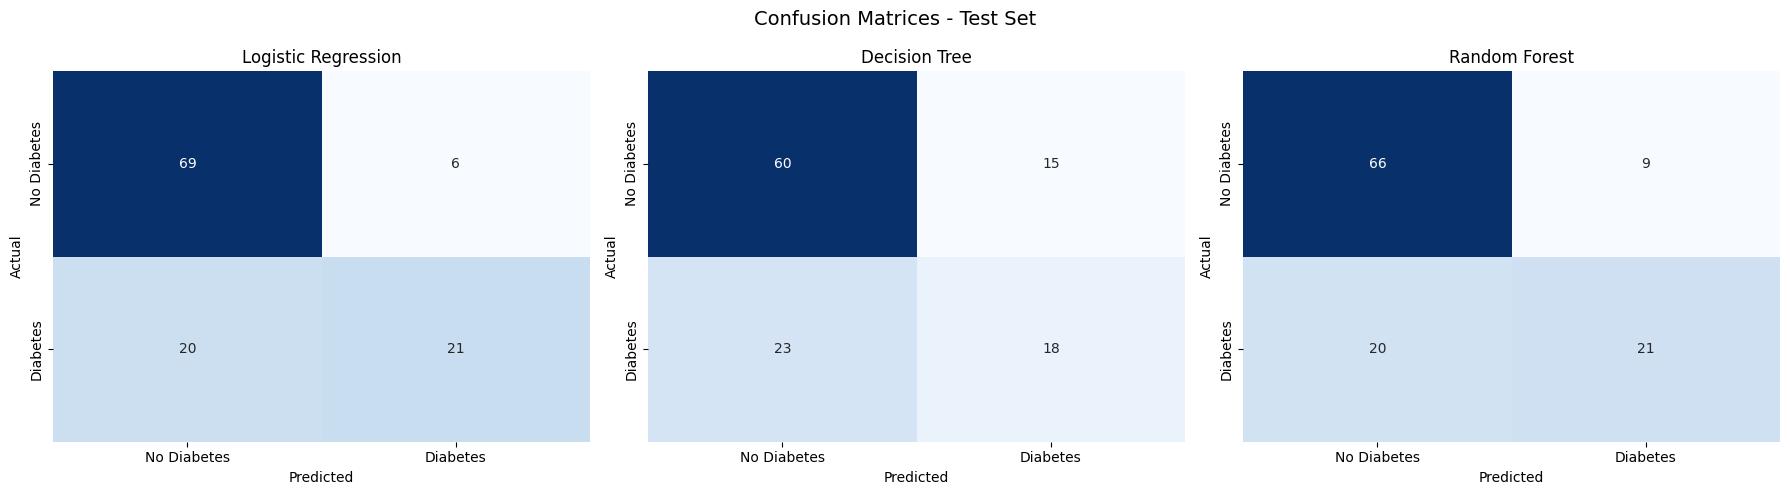

In [60]:
# Confusion Matrices - Test Set

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_cm = [
    ('Logistic Regression', y_pred_lr_test),
    ('Decision Tree', y_pred_dt_test),
    ('Random Forest', y_pred_rf_test)
]

for ax, (name, y_pred) in zip(axes, models_cm):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices - Test Set', fontsize=14)
plt.tight_layout()
plt.show()

## Final Model Comparison

The three machine learning models were evaluated on both the validation and test sets using Accuracy, Precision, Recall, and F1-score.

The validation results were used to compare model performance during development, while the test set was kept untouched until the final evaluation.

Random Forest was selected as the final model because it showed strong and consistent performance across both validation and test sets.

In [61]:
# Final Comparison: Validation vs Test

final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    
    'Validation Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    
    'Validation Precision': [
        lr_precision,
        dt_precision,
        rf_precision
    ],
    
    'Validation Recall': [
        lr_recall,
        dt_recall,
        rf_recall
    ],
    
    'Validation F1-score': [
        lr_f1,
        dt_f1,
        rf_f1
    ],
    
    'Test Accuracy': [
        lr_test_accuracy,
        dt_test_accuracy,
        rf_test_accuracy
    ],
    
    'Test Precision': [
        lr_test_precision,
        dt_test_precision,
        rf_test_precision
    ],
    
    'Test Recall': [
        lr_test_recall,
        dt_test_recall,
        rf_test_recall
    ],
    
    'Test F1-score': [
        lr_test_f1,
        dt_test_f1,
        rf_test_f1
    ]
})

final_results

,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Logistic Regression,0.713043,0.594595,0.550,0.571429,0.775862,0.777778,0.512195,0.617647
1,Decision Tree,0.721739,0.595238,0.625,0.609756,0.672414,0.545455,0.439024,0.486486
2,Random Forest,0.747826,0.648649,0.600,0.623377,0.750000,0.700000,0.512195,0.591549


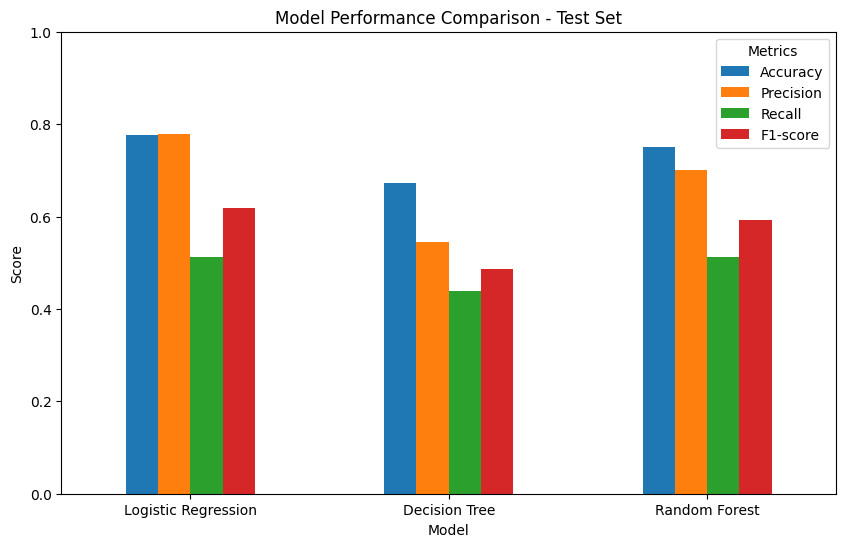

In [62]:
# Test Set Performance Comparison

test_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        lr_test_accuracy,
        dt_test_accuracy,
        rf_test_accuracy
    ],
    'Precision': [
        lr_test_precision,
        dt_test_precision,
        rf_test_precision
    ],
    'Recall': [
        lr_test_recall,
        dt_test_recall,
        rf_test_recall
    ],
    'F1-score': [
        lr_test_f1,
        dt_test_f1,
        rf_test_f1
    ]
})

test_results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison - Test Set')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.show()

## Discussion

The three classification models showed different performance patterns across the validation and test sets.

On the validation set, Random Forest achieved the highest Accuracy (74.78%), Precision (64.86%), and F1-score (62.34%), while Decision Tree achieved the highest Recall (62.50%). This indicates that Random Forest provided the strongest overall validation performance.

On the test set, Logistic Regression achieved the highest Accuracy (77.59%), Precision (77.78%), and F1-score (61.76%). Random Forest achieved an Accuracy of 75.00%, Precision of 70.00%, Recall of 51.22%, and F1-score of 59.15%. Decision Tree showed the lowest test performance, particularly in Recall (43.90%).

Although Logistic Regression achieved slightly better overall test metrics, Random Forest was selected as the final model because it demonstrated strong validation performance and maintained a stable test accuracy compared with its validation accuracy.

The confusion matrices also showed that Random Forest produced 20 false negatives on the test set, compared with 20 for Logistic Regression and 23 for Decision Tree. Since false negatives represent diabetic patients incorrectly classified as non-diabetic, Recall is an important metric in a medical screening context.

However, the relatively moderate Recall of Random Forest (51.22%) indicates that the model should be considered a proof-of-concept rather than a clinically deployable diagnostic system. Further model optimization, threshold tuning, and external clinical validation would be required before real-world use.